In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
dataset_path = None

# Search for the CSV in the current folder and subfolders
for root, dirs, files in os.walk(os.getcwd()):
    if "hotel_bookings.csv" in files:
        dataset_path = os.path.join(root, "hotel_bookings.csv")
        break

if dataset_path:
    print("Dataset found:", dataset_path)

    df = pd.read_csv(dataset_path)

    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)

    display(df.head())
else:
    print("Dataset not found!")
    print("Place hotel_bookings.csv inside your project folder.")

Dataset found: C:\Users\Shaik Suhail\New Project\Hotel_Booking_EDA\dataset\hotel_bookings.csv
Dataset loaded successfully!
Dataset shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
# First five records
display(df.head())

# Last five records
display(df.tail())

# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Dataset information
df.info()

# Numerical summary
display(df.describe())

# Categorical summary
display(df.describe(include="object"))

# Data types
display(df.dtypes)

# Missing values
print("\nMissing values:")
display(df.isnull().sum()[df.isnull().sum() > 0])

# Duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# Unique values
for column in df.columns:
    print(column, ":", df[column].nunique())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,0.0,0,BB,BEL,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,0.0,0,BB,FRA,Online TA,TA/TO,0,0,0,E,E,0,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,0.0,0,BB,DEU,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,0.0,0,HB,DEU,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


Rows: 119390
Columns: 32
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int6

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-10-21
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461


hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent                             


Missing values:


children         4
country        488
agent        16340
company     112593
dtype: int64


Duplicate records: 31994
hotel : 2
is_canceled : 2
lead_time : 479
arrival_date_year : 3
arrival_date_month : 12
arrival_date_week_number : 53
arrival_date_day_of_month : 31
stays_in_weekend_nights : 17
stays_in_week_nights : 35
adults : 14
children : 5
babies : 5
meal : 5
country : 177
market_segment : 8
distribution_channel : 5
is_repeated_guest : 2
previous_cancellations : 15
previous_bookings_not_canceled : 73
reserved_room_type : 10
assigned_room_type : 12
booking_changes : 21
deposit_type : 3
agent : 333
company : 352
days_in_waiting_list : 128
customer_type : 4
adr : 8879
required_car_parking_spaces : 5
total_of_special_requests : 6
reservation_status : 3
reservation_status_date : 926


In [4]:
# Create copies
df_raw = df.copy()
df_clean = df.copy()

# Missing value report
missing_report = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().sum() / len(df_clean)
    ) * 100
})

display(
    missing_report[missing_report["Missing Count"] > 0]
    .sort_values("Missing Percentage", ascending=False)
)

,Missing Count,Missing Percentage
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350


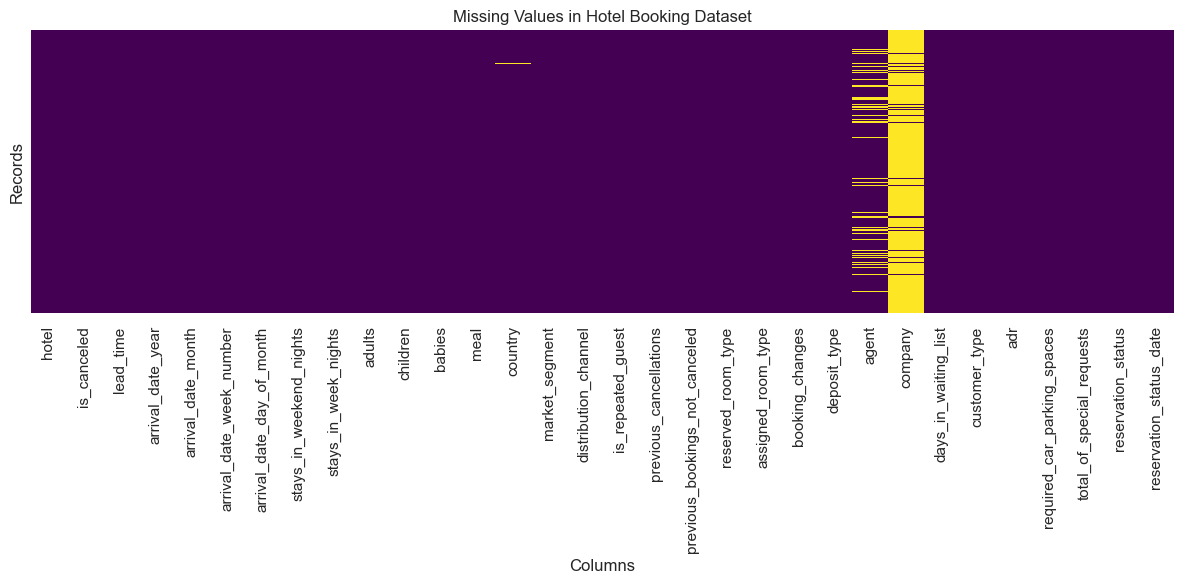

In [5]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df_clean.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values in Hotel Booking Dataset")
plt.xlabel("Columns")
plt.ylabel("Records")

plt.tight_layout()
plt.show()

In [6]:
df_clean["country"] = df_clean["country"].fillna(
    df_clean["country"].mode()[0]
)

df_clean["children"] = df_clean["children"].fillna(0)
df_clean["agent"] = df_clean["agent"].fillna(0)
df_clean["company"] = df_clean["company"].fillna(0)

print("Missing values handled!")

Missing values handled!


In [7]:
duplicate_count = df_clean.duplicated().sum()

print("Duplicates before cleaning:", duplicate_count)

df_clean = df_clean.drop_duplicates()

print("Duplicates after cleaning:", df_clean.duplicated().sum())

Duplicates before cleaning: 32013
Duplicates after cleaning: 0


In [8]:
df_clean["reservation_status_date"] = pd.to_datetime(
    df_clean["reservation_status_date"],
    errors="coerce"
)

print("Date conversion completed!")

Date conversion completed!


In [9]:
invalid_guests = df_clean[
    (df_clean["adults"] == 0) &
    (df_clean["children"] == 0) &
    (df_clean["babies"] == 0)
]

print("Zero-guest records:", len(invalid_guests))

df_clean = df_clean[
    (df_clean["adults"] +
     df_clean["children"] +
     df_clean["babies"]) > 0
].copy()

print("Zero-guest records removed!")

Zero-guest records: 166
Zero-guest records removed!


In [10]:
negative_adr = df_clean[df_clean["adr"] < 0]

print("Negative ADR records:", len(negative_adr))

df_clean = df_clean[df_clean["adr"] >= 0].copy()

print("Negative ADR records removed!")

Negative ADR records: 1
Negative ADR records removed!


In [11]:
Q1 = df_clean["adr"].quantile(0.25)
Q3 = df_clean["adr"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

adr_outliers = df_clean[
    (df_clean["adr"] < lower_limit) |
    (df_clean["adr"] > upper_limit)
]

print("ADR outliers:", len(adr_outliers))
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

ADR outliers: 2506
Lower limit: -20.52499999999999
Upper limit: 226.875


In [12]:
Q1 = df_clean["lead_time"].quantile(0.25)
Q3 = df_clean["lead_time"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

lead_time_outliers = df_clean[
    (df_clean["lead_time"] < lower_limit) |
    (df_clean["lead_time"] > upper_limit)
]

print("Lead-time outliers:", len(lead_time_outliers))

Lead-time outliers: 2394


In [13]:
cleaning_summary = pd.DataFrame({
    "Issue": [
        "Missing Values",
        "Duplicate Records",
        "Invalid Guest Records",
        "Negative ADR",
        "ADR Outliers",
        "Lead Time Outliers"
    ],
    "Action": [
        "Imputed or marked as unrecorded",
        "Removed exact duplicates",
        "Removed zero-guest records",
        "Removed negative ADR records",
        "Identified and retained",
        "Identified and retained"
    ]
})

display(cleaning_summary)

,Issue,Action
0,Missing Values,Imputed or marked as unrecorded
1,Duplicate Records,Removed exact duplicates
2,Invalid Guest Records,Removed zero-guest records
3,Negative ADR,Removed negative ADR records
4,ADR Outliers,Identified and retained
5,Lead Time Outliers,Identified and retained


In [14]:
# Create the output folder relative to the notebook
os.makedirs("../dataset", exist_ok=True)

df_clean.to_csv(
    "../dataset/hotel_bookings_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Final cleaned shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())

Cleaned dataset saved successfully!
Final cleaned shape: (87210, 32)
Remaining missing values: 0


In [15]:
hotel_counts = df_clean["hotel"].value_counts()

hotel_percentage = (
    df_clean["hotel"].value_counts(normalize=True) * 100
)

print("Hotel booking counts:")
display(hotel_counts)

print("Hotel booking percentages:")
display(hotel_percentage.round(2))

Hotel booking counts:


hotel
City Hotel      53274
Resort Hotel    33936
Name: count, dtype: int64

Hotel booking percentages:


hotel
City Hotel      61.09
Resort Hotel    38.91
Name: proportion, dtype: float64

In [16]:
cancellation_counts = df_clean["is_canceled"].value_counts()

cancellation_rate = df_clean["is_canceled"].mean() * 100

print("Cancellation counts:")
display(cancellation_counts)

print("Cancellation rate:", round(cancellation_rate, 2), "%")

Cancellation counts:


is_canceled
0    63202
1    24008
Name: count, dtype: int64

Cancellation rate: 27.53 %


In [17]:
months = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_bookings = (
    df_clean["arrival_date_month"]
    .value_counts()
    .reindex(months)
)

display(monthly_bookings)

print("Highest booking month:", monthly_bookings.idxmax())
print("Lowest booking month:", monthly_bookings.idxmin())

arrival_date_month
January       4683
February      6077
March         7485
April         7897
May           8344
June          7756
July         10042
August       11242
September     6682
October       6919
November      4973
December      5110
Name: count, dtype: int64

Highest booking month: August
Lowest booking month: January


In [18]:
print("Average ADR:", round(df_clean["adr"].mean(), 2))
print("Median ADR:", round(df_clean["adr"].median(), 2))
print("Minimum ADR:", round(df_clean["adr"].min(), 2))
print("Maximum ADR:", round(df_clean["adr"].max(), 2))

adr_by_hotel = df_clean.groupby("hotel")["adr"].mean()

display(adr_by_hotel)

Average ADR: 106.53
Median ADR: 98.25
Minimum ADR: 0.0
Maximum ADR: 5400.0


hotel
City Hotel      111.271969
Resort Hotel     99.078798
Name: adr, dtype: float64

In [19]:
market_analysis = df_clean["market_segment"].value_counts()

market_percentage = (
    df_clean["market_segment"].value_counts(normalize=True) * 100
)

display(market_analysis)
display(market_percentage.round(2))

market_segment
Online TA        51551
Offline TA/TO    13852
Direct           11774
Groups            4919
Corporate         4194
Complementary      692
Aviation           226
Undefined            2
Name: count, dtype: int64

market_segment
Online TA        59.11
Offline TA/TO    15.88
Direct           13.50
Groups            5.64
Corporate         4.81
Complementary     0.79
Aviation          0.26
Undefined         0.00
Name: proportion, dtype: float64

In [20]:
customer_analysis = df_clean["customer_type"].value_counts()

display(customer_analysis)

customer_type
Transient          71848
Transient-Party    11686
Contract            3135
Group                541
Name: count, dtype: int64

In [21]:
hotel_cancellation = pd.crosstab(
    df_clean["hotel"],
    df_clean["is_canceled"],
    normalize="index"
) * 100

hotel_cancellation.columns = [
    "Not Cancelled (%)",
    "Cancelled (%)"
]

display(hotel_cancellation)

,Not Cancelled (%),Cancelled (%)
hotel,,
City Hotel,69.900890,30.099110
Resort Hotel,76.505776,23.494224


In [22]:
print("Average lead time:", round(df_clean["lead_time"].mean(), 2))
print("Median lead time:", df_clean["lead_time"].median())
print("Maximum lead time:", df_clean["lead_time"].max())

Average lead time: 79.98
Median lead time: 49.0
Maximum lead time: 737


In [23]:
special_requests = (
    df_clean["total_of_special_requests"]
    .value_counts()
    .sort_index()
)

display(special_requests)

total_of_special_requests
0    43775
1    28972
2    11794
3     2313
4      320
5       36
Name: count, dtype: int64

In [24]:
eda_summary = pd.DataFrame({
    "Metric": [
        "Total Bookings",
        "City Hotel Bookings",
        "Resort Hotel Bookings",
        "Cancellation Rate (%)",
        "Average ADR",
        "Average Lead Time",
        "Highest Booking Month",
        "Most Popular Market Segment",
        "Most Common Customer Type"
    ],
    "Value": [
        len(df_clean),
        hotel_counts.get("City Hotel", 0),
        hotel_counts.get("Resort Hotel", 0),
        round(cancellation_rate, 2),
        round(df_clean["adr"].mean(), 2),
        round(df_clean["lead_time"].mean(), 2),
        monthly_bookings.idxmax(),
        market_analysis.idxmax(),
        customer_analysis.idxmax()
    ]
})

display(eda_summary)

,Metric,Value
0,Total Bookings,87210
1,City Hotel Bookings,53274
2,Resort Hotel Bookings,33936
3,Cancellation Rate (%),27.53
4,Average ADR,106.53
5,Average Lead Time,79.98
6,Highest Booking Month,August
7,Most Popular Market Segment,Online TA
8,Most Common Customer Type,Transient


In [25]:
os.makedirs("../outputs", exist_ok=True)

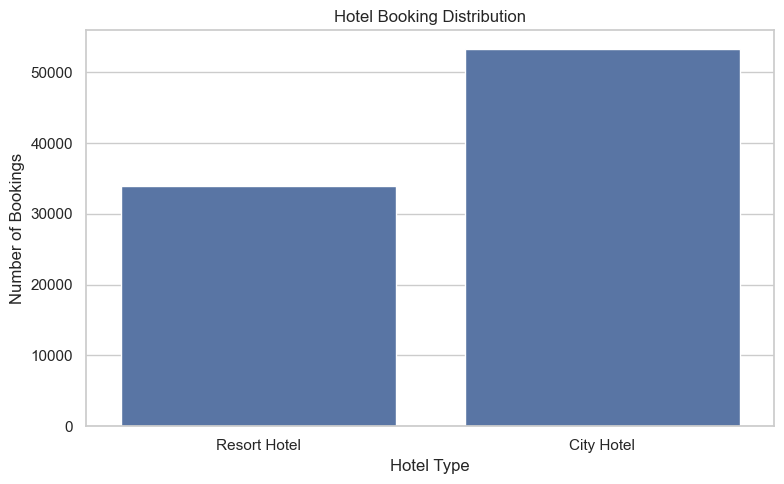

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x="hotel")

plt.title("Hotel Booking Distribution")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.savefig("../outputs/hotel_distribution.png", dpi=300)
plt.show()

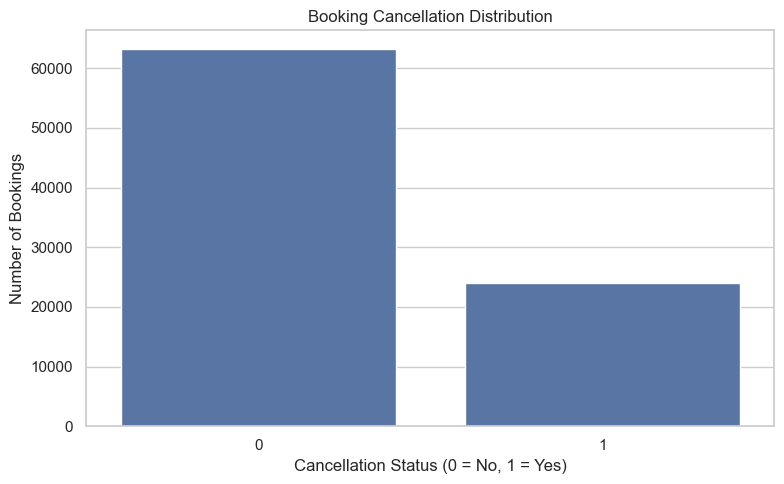

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x="is_canceled")

plt.title("Booking Cancellation Distribution")
plt.xlabel("Cancellation Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.savefig("../outputs/cancellation_distribution.png", dpi=300)
plt.show()

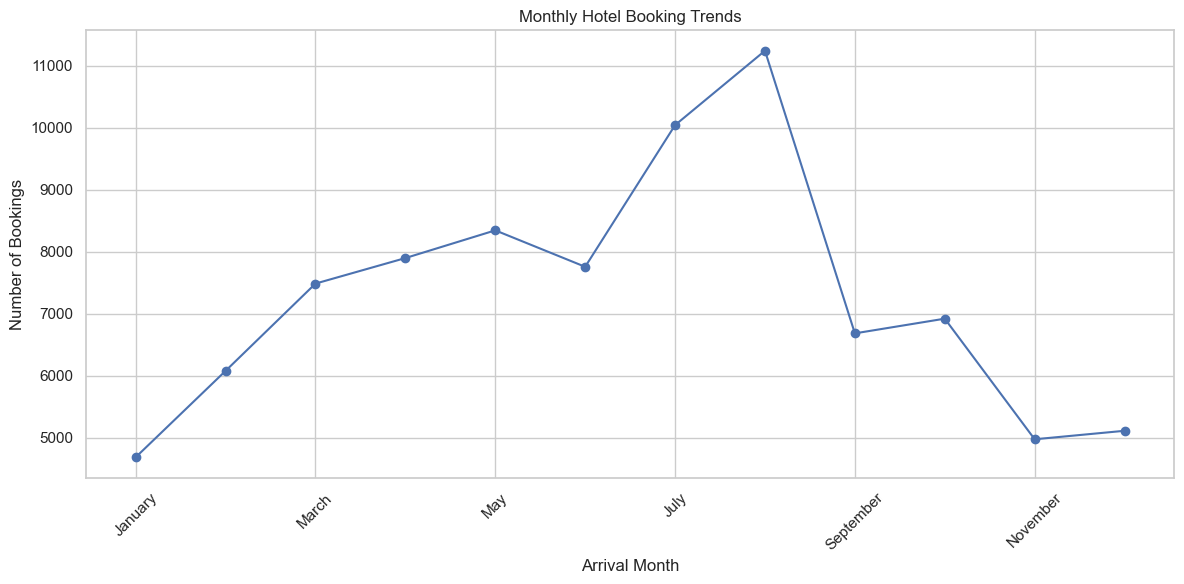

In [28]:
plt.figure(figsize=(12, 6))

monthly_bookings.plot(kind="line", marker="o")

plt.title("Monthly Hotel Booking Trends")
plt.xlabel("Arrival Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("../outputs/monthly_booking_trends.png", dpi=300)
plt.show()

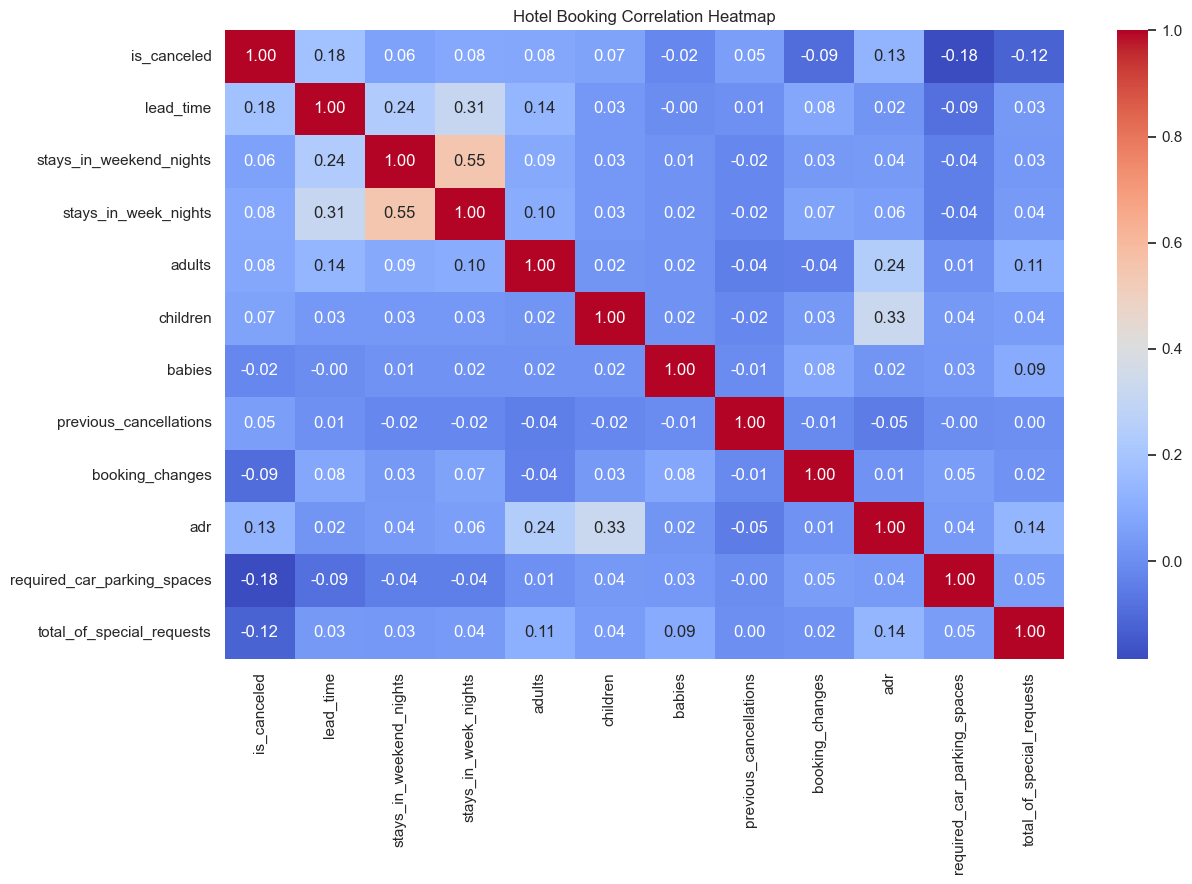

In [29]:
numeric_columns = [
    "is_canceled",
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "booking_changes",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

correlation = df_clean[numeric_columns].corr()

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Hotel Booking Correlation Heatmap")

plt.tight_layout()
plt.savefig("../outputs/correlation_heatmap.png", dpi=300)
plt.show()

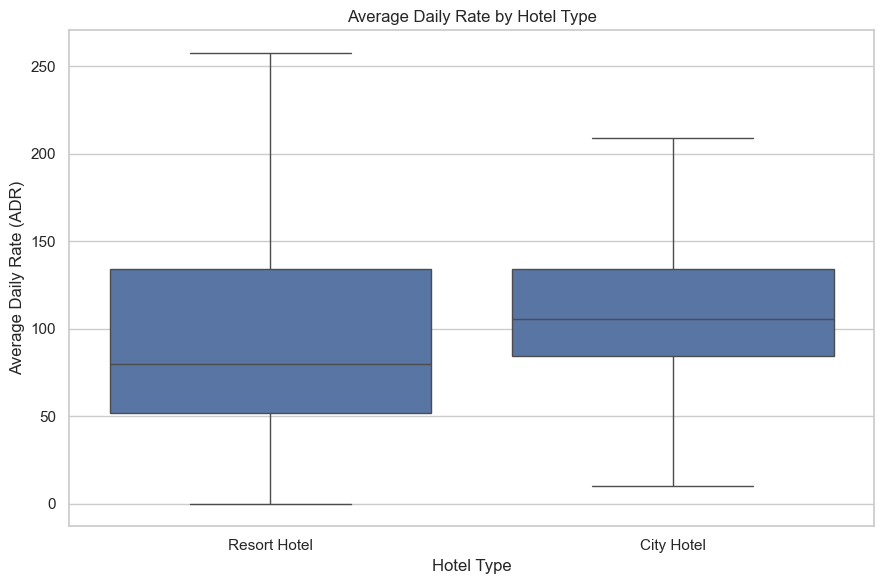

In [30]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df_clean,
    x="hotel",
    y="adr",
    showfliers=False
)

plt.title("Average Daily Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Average Daily Rate (ADR)")

plt.tight_layout()
plt.savefig("../outputs/adr_comparison.png", dpi=300)
plt.show()

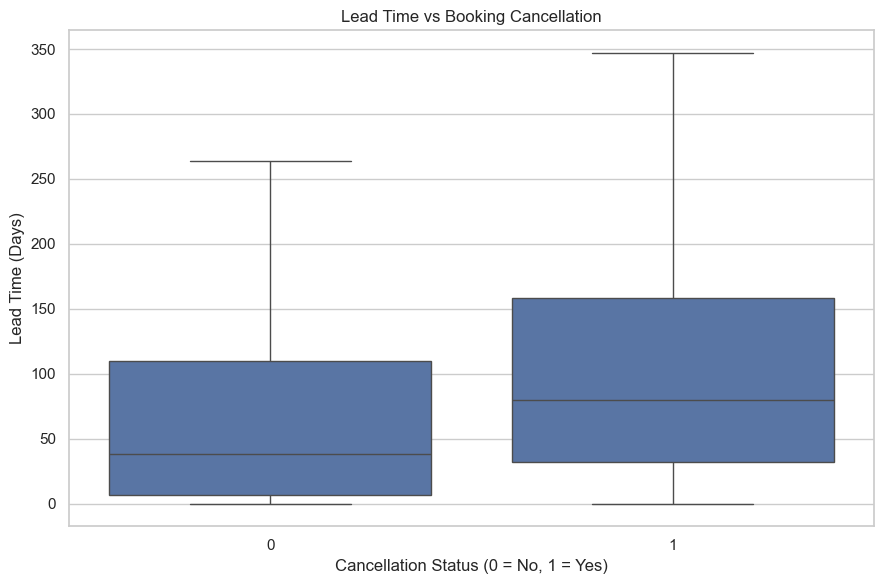

In [31]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df_clean,
    x="is_canceled",
    y="lead_time",
    showfliers=False
)

plt.title("Lead Time vs Booking Cancellation")
plt.xlabel("Cancellation Status (0 = No, 1 = Yes)")
plt.ylabel("Lead Time (Days)")

plt.tight_layout()
plt.savefig("../outputs/lead_time_analysis.png", dpi=300)
plt.show()

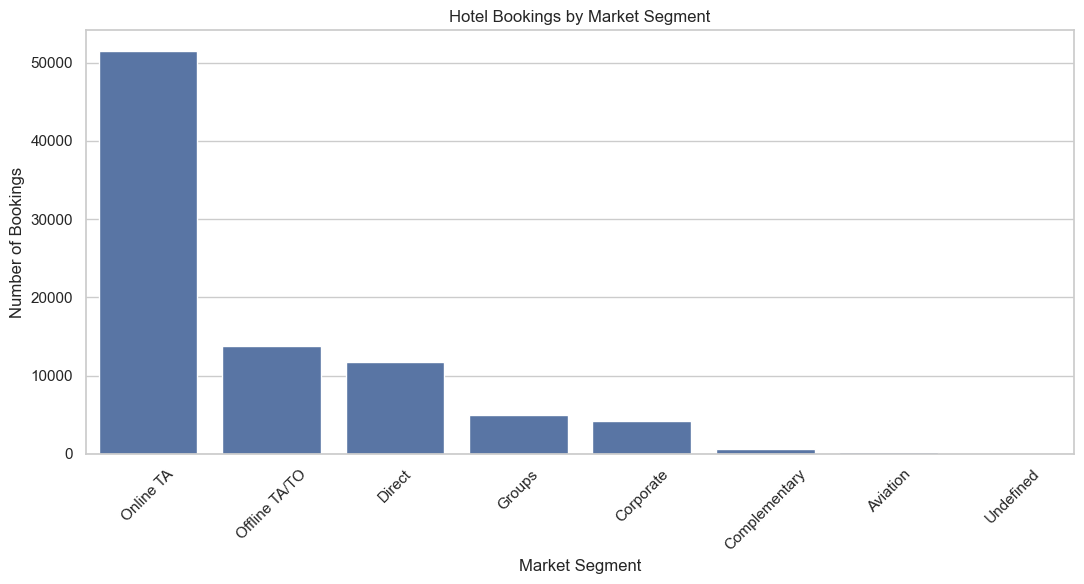

In [32]:
plt.figure(figsize=(11, 6))

market_order = df_clean["market_segment"].value_counts().index

sns.countplot(
    data=df_clean,
    x="market_segment",
    order=market_order
)

plt.title("Hotel Bookings by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("../outputs/market_segment_distribution.png", dpi=300)
plt.show()

In [33]:
cancelled = df_clean.loc[
    df_clean["is_canceled"] == 1,
    "lead_time"
]

not_cancelled = df_clean.loc[
    df_clean["is_canceled"] == 0,
    "lead_time"
]

t_stat, t_p = stats.ttest_ind(
    cancelled,
    not_cancelled,
    equal_var=False
)

print("Welch Independent Samples T-Test")
print("--------------------------------")
print("Cancelled mean:", round(cancelled.mean(), 2))
print("Not cancelled mean:", round(not_cancelled.mean(), 2))
print("T-statistic:", round(t_stat, 4))
print("P-value:", t_p)

if t_p < 0.05:
    print("Reject H0: Mean lead times are significantly different.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

Welch Independent Samples T-Test
--------------------------------
Cancelled mean: 105.74
Not cancelled mean: 70.2
T-statistic: 52.5763
P-value: 0.0
Reject H0: Mean lead times are significantly different.


In [34]:
contingency_table = pd.crosstab(
    df_clean["hotel"],
    df_clean["is_canceled"]
)

chi2, chi_p, dof, expected = stats.chi2_contingency(
    contingency_table
)

print("Chi-Square Test")
print("----------------")
display(contingency_table)

print("Chi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", dof)
print("P-value:", chi_p)

if chi_p < 0.05:
    print("Reject H0: Hotel type is associated with cancellation.")
else:
    print("Fail to reject H0: Insufficient evidence of association.")

Chi-Square Test
----------------


is_canceled,0,1
hotel,,
City Hotel,37239,16035
Resort Hotel,25963,7973


Chi-square statistic: 452.9694
Degrees of freedom: 1
P-value: 1.6289373977458632e-100
Reject H0: Hotel type is associated with cancellation.


In [35]:
pearson_r, pearson_p = stats.pearsonr(
    df_clean["lead_time"],
    df_clean["adr"]
)

print("Pearson Correlation Test")
print("------------------------")
print("Correlation coefficient:", round(pearson_r, 4))
print("P-value:", pearson_p)

if pearson_p < 0.05:
    print("Reject H0: A statistically significant linear correlation exists.")
else:
    print("Fail to reject H0: Insufficient evidence of linear correlation.")

Pearson Correlation Test
------------------------
Correlation coefficient: 0.0219
P-value: 1.0772340572115255e-10
Reject H0: A statistically significant linear correlation exists.


In [36]:
statistical_summary = pd.DataFrame({
    "Test": [
        "Welch Independent T-Test",
        "Chi-Square Test",
        "Pearson Correlation"
    ],
    "Statistic": [
        t_stat,
        chi2,
        pearson_r
    ],
    "P-Value": [
        t_p,
        chi_p,
        pearson_p
    ],
    "Conclusion": [
        "Significant difference" if t_p < 0.05 else "Not significant",
        "Associated" if chi_p < 0.05 else "Not significant",
        "Significant correlation" if pearson_p < 0.05 else "Not significant"
    ]
})

display(statistical_summary)

,Test,Statistic,P-Value,Conclusion
0,Welch Independent T-Test,52.576295,0.000000e+00,Significant difference
1,Chi-Square Test,452.969364,1.628937e-100,Associated
2,Pearson Correlation,0.021858,1.077234e-10,Significant correlation


In [37]:
final_findings = pd.DataFrame({
    "Finding": [
        "Total Bookings",
        "Most Booked Hotel",
        "Cancellation Rate",
        "Highest Booking Month",
        "Lowest Booking Month",
        "Average ADR",
        "Most Popular Market Segment",
        "Most Common Customer Type",
        "Average Lead Time"
    ],
    "Result": [
        len(df_clean),
        hotel_counts.idxmax(),
        f"{cancellation_rate:.2f}%",
        monthly_bookings.idxmax(),
        monthly_bookings.idxmin(),
        round(df_clean["adr"].mean(), 2),
        market_analysis.idxmax(),
        customer_analysis.idxmax(),
        round(df_clean["lead_time"].mean(), 2)
    ]
})

display(final_findings)

,Finding,Result
0,Total Bookings,87210
1,Most Booked Hotel,City Hotel
2,Cancellation Rate,27.53%
3,Highest Booking Month,August
4,Lowest Booking Month,January
5,Average ADR,106.53
6,Most Popular Market Segment,Online TA
7,Most Common Customer Type,Transient
8,Average Lead Time,79.98


In [38]:
os.makedirs("../outputs", exist_ok=True)

eda_summary.to_csv(
    "../outputs/eda_summary.csv",
    index=False
)

cleaning_summary.to_csv(
    "../outputs/cleaning_summary.csv",
    index=False
)

statistical_summary.to_csv(
    "../outputs/statistical_test_results.csv",
    index=False
)

final_findings.to_csv(
    "../outputs/final_findings.csv",
    index=False
)

print("All reports exported successfully!")

All reports exported successfully!


In [39]:
print("Generated files:")

for root, dirs, files in os.walk("../outputs"):
    for file in sorted(files):
        print(file)

Generated files:
adr_comparison.png
cancellation_distribution.png
cleaning_summary.csv
correlation_heatmap.png
eda_summary.csv
final_findings.csv
hotel_distribution.png
lead_time_analysis.png
market_segment_distribution.png
monthly_booking_trends.png
statistical_test_results.csv
